# A subagent harness from scratch: handoffs, messages, blocking and not blocking

**Goal.** Build, in one notebook and without an agent framework, a harness in which a main agent hands work
to subagents and the subagents send messages back, while the main agent either **keeps working** or
**chooses to block** until it needs an answer. The harness grows one pattern at a time, and every pattern is
run with real LLM agents on the same task, so the cost and benefit of each step is measured, not asserted.

| Level | Pattern | New primitive |
|---|---|---|
| 0 | One agent does everything | (baseline) |
| 1 | Synchronous handoff: the main agent blocks until the subagent returns | `handoff` |
| 2 | Asynchronous handoff: spawn, keep working, wait only when the result is needed | `spawn`, `wait`, `wait_all` |
| 3 | Progress messages up, instructions down: a subagent reports a tool failure and the main agent can redirect it | `report`, `send`, `wait_for_message` |
| 4 | A subagent asks the main agent a question and blocks until it gets the answer | `ask_parent` |
| 5 | Hedging: three subagents race, the first result wins, the rest are cancelled | `wait_any`, `cancel` |
| 6 | Nested delegation: subagents spawn their own subagents; results route up two levels | depth 2 |

**The task.** Plan a trip for two from Toronto to Lisbon, Rome and Prague (two nights each) and back: cheapest
flight per leg, cheapest hotel rated 4.0 or more, preferring a central hotel when it costs at most €10 a night
more. The tools are simulated with fixed data and real delays (2-5 s per call), so the correct total is known
(**€3,316**) and parallelism shows up in wall-clock time.

**Models.** Agents run on Claude through the `claude -p` CLI: Sonnet 5.5 for the main agent, Haiku 5.5 for
subagents (the cheap-worker pattern). Both are configurable, and `BACKEND` can switch every agent to `codex` or
`muse`.

**Headline result.** All seven levels produced the correct plan (€3,316).
* **Not blocking is where the time goes.** Asynchronous spawning finished in 57 s against 82 s for one agent. A
  synchronous handoff was slower than no subagents at all (120 s): the planner sat blocked for 55% of the run.
* **Messages in both directions work, with one gap.** A subagent asked a question and was blocked for 11 s while
  the planner kept working, then continued with the answer. Another hit a failing tool, ignored its "wait for
  instructions" rule, recovered on its own and reported; the planner's reply reached it after it had finished and
  was never read. A harness should report when a message goes to an agent that has already finished.
* **Racing three scouts** returned the fastest provider's answer in 49 s and cancelled the other two mid-search.
* **Nesting two levels deep** cost 35 LLM calls instead of 11, and the final answer picked up weather figures that
  no tool returned.

## Contents
1. Setup
2. The simulated world and the correct answer
3. The harness: runtime, agents, messages, blocking
4. Prompts and action definitions
5. Recording runs and drawing timelines
6. Levels 0-2: from one agent to asynchronous handoffs
7. Levels 3-4: messages in both directions
8. Levels 5-6: racing and nested delegation
9. Comparison across levels
10. Design notes, limitations, reproduction

## 1. Setup
Runs are recorded to `data/runs/*.json`. By default the notebook **replays** recorded runs, because a live
multi-agent run is not deterministic (message timing changes what each agent sees). Set `LIVE = True`, or delete
a run file, to run the agents again; a full live pass makes about 150 CLI calls and takes 10-15 minutes.

In [1]:
import json, os, queue, re, shutil, subprocess, tempfile, threading, time, uuid, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from cycler import cycler
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

ROOT = Path.cwd()
DATA, FIG = ROOT / "data", ROOT / "figures"
RUNS = DATA / "runs"
for d in (DATA, FIG, RUNS):
    d.mkdir(parents=True, exist_ok=True)

LIVE = os.environ.get("NB_LIVE") == "1"   # True: re-run every level; otherwise only levels without a recording run
BACKEND = "claude"                        # "claude", "codex" or "muse" for every agent
MAIN_MODEL = {"claude": "claude-sonnet-5-5", "codex": "gpt-6.1-sol", "muse": "muse-wonder-full-1.0"}[BACKEND]
SUB_MODEL = {"claude": "claude-haiku-5-5", "codex": "gpt-6.1-sol", "muse": "muse-wonder-full-1.0"}[BACKEND]
EFFORT = "low"
MAX_STEPS = 18                            # per agent; a stuck agent gives up after this many LLM calls

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight", "figure.facecolor": "white",
    "axes.facecolor": "white", "axes.edgecolor": GRID, "axes.labelcolor": INK, "axes.titleweight": "bold",
    "axes.titlesize": 11, "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 9.5, "legend.frameon": False,
    "axes.prop_cycle": cycler(color=PALETTE),
})
warnings.filterwarnings("ignore", category=FutureWarning)

## 2. The simulated world and the correct answer
Fixed tables stand in for flight and hotel search. Each tool sleeps for a set time to imitate a slow API, so
an agent that waits on three hotel searches in a row loses about 12 seconds that parallel subagents can save.

In [2]:
FLIGHTS = {  # (origin, destination) -> [(flight, € per person)]
    ("Toronto", "Lisbon"): [("TP 258", 612), ("AC 832", 655)],
    ("Lisbon", "Rome"): [("TP 838", 89), ("FR 2181", 61)],
    ("Rome", "Prague"): [("OK 5813", 112), ("FR 3354", 74)],
    ("Prague", "Toronto"): [("LH 1397", 580), ("AC 885", 640)],
}
HOTELS = {  # city -> [(hotel, rating, € per room per night, location)]
    "Lisbon": [("Casa Alfama", 4.6, 142, "central"), ("Baixa Rooms", 4.1, 96, "central"), ("Oriente Park", 3.8, 71, "outskirts")],
    "Rome": [("Trastevere Suites", 4.4, 168, "central"), ("Termini Inn", 4.0, 104, "central"), ("Via Appia Lodge", 4.0, 98, "outskirts")],
    "Prague": [("Old Town Loft", 4.7, 131, "central"), ("Vltava Boat Hotel", 3.9, 64, "central"), ("Zizkov Hostel", 3.6, 38, "outskirts")],
}
WEATHER = {"Lisbon": "May: 22°C highs, 6 rain days", "Rome": "May: 24°C highs, 7 rain days", "Prague": "May: 19°C highs, 11 rain days"}
LATENCY = {"search_flights": 3.0, "search_hotels": 4.0, "search_hotels_backup": 5.0, "get_weather": 2.0}
PROVIDER_LATENCY = {"skyscan": 2.0, "farefinder": 6.0, "airdeal": 14.0}   # level 5: same data, different speed


def correct_plan():
    flights = sum(min(p for _, p in opts) for opts in FLIGHTS.values()) * 2
    hotels = {}
    for city, hs in HOTELS.items():
        ok = sorted([h for h in hs if h[1] >= 4.0], key=lambda h: h[2])
        best = ok[0]
        central = [h for h in ok if h[3] == "central" and h[2] - best[2] <= 10]
        hotels[city] = (central[0] if central and best[3] != "central" else best)
    total = flights + sum(h[2] * 2 for h in hotels.values())
    return total, {c: h[0] for c, h in hotels.items()}


EXPECTED_TOTAL, EXPECTED_HOTELS = correct_plan()
print(f"Correct plan: total €{EXPECTED_TOTAL:,} with hotels {EXPECTED_HOTELS}")
print("Without the central-location preference Rome would be Via Appia Lodge and the total €3,310.")

Correct plan: total €3,316 with hotels {'Lisbon': 'Baixa Rooms', 'Rome': 'Termini Inn', 'Prague': 'Old Town Loft'}
Without the central-location preference Rome would be Via Appia Lodge and the total €3,310.


## 3. The harness
Four pieces, all in this cell:

* **`Runtime`** owns the agents, the LLM call, the clock and the event log. Every LLM call, tool call and
  blocked interval is recorded as a *span*; every message is a timestamped *event*.
* **`Agent`** is a thread with an **inbox** (`queue.Queue`). Each step it moves new inbox messages into its
  prompt, asks the LLM for one action as JSON, and executes it.
* **Messages** are small dicts: `result` (child finished), `progress` (child report), `question` (child asks),
  `instruction` (parent to child). Messages that arrive while an agent is busy are shown to it on its next
  step, so a running agent never misses one.
* **Blocking** is explicit. `handoff`, `wait`, `wait_any`, `wait_all`, `ask_parent` and `wait_for_message` block
  the calling agent on its inbox until a matching message arrives (or a timeout). Non-matching messages that
  arrive meanwhile are kept for later. Every other action returns immediately, so the agent keeps working.

Cancellation is cooperative: `cancel` sets a flag that the child checks between steps, during blocking waits
and during tool calls. A cancelled child still sends a `result` ("cancelled before finishing"), so nobody is
left waiting for it.

In [3]:
CLAUDE, CODEX, MUSE = shutil.which("claude"), shutil.which("codex"), shutil.which("muse")
WORKDIR = Path(tempfile.mkdtemp(prefix="nb08_"))


def llm(model, prompt, timeout=600):
    """One stateless LLM call through a CLI. Returns the reply text."""
    if BACKEND == "claude":
        r = subprocess.run([CLAUDE, "-p", "--model", model, "--tools", "", "--safe-mode", "--no-session-persistence",
                            "--effort", EFFORT, "--output-format", "json"], input=prompt, capture_output=True,
                           text=True, encoding="utf-8", timeout=timeout, cwd=WORKDIR)
        return json.loads(r.stdout)["result"]
    if BACKEND == "codex":
        r = subprocess.run([CODEX, "exec", "--skip-git-repo-check", "--ephemeral", "--ignore-user-config", "--sandbox",
                            "read-only", "-m", model, "-c", f"model_reasoning_effort={EFFORT}", "--json", "-"],
                           input=prompt, capture_output=True, text=True, encoding="utf-8", timeout=timeout, cwd=WORKDIR)
        msgs = [json.loads(l) for l in r.stdout.splitlines() if l.startswith("{")]
        return [m["item"]["text"] for m in msgs if m.get("type") == "item.completed" and m["item"].get("type") == "agent_message"][-1]
    pf = WORKDIR / f"p_{uuid.uuid4().hex}.txt"
    pf.write_text(prompt, encoding="utf-8")
    r = subprocess.run([MUSE, "exec", "--preset", "empty", "--no-session-log", "--disable-web-tools", "--model", model,
                        "--reasoning-effort", EFFORT, "--prompt-file", str(pf)], capture_output=True, text=True,
                       encoding="utf-8", timeout=timeout, cwd=WORKDIR)
    return r.stdout.strip()


class Cancelled(Exception):
    pass


class Runtime:
    def __init__(self, level, roles, world=None):
        self.level, self.roles, self.world = level, roles, world or {}
        self.t0 = time.perf_counter()
        self.lock = threading.Lock()
        self.agents, self.spans, self.events, self.llm_log = {}, [], [], []
        self.final, self.final_t, self.done = None, None, threading.Event()
        self.calls = {"llm": 0, "tool": 0}
        self.counter = 0

    def now(self):
        return round(time.perf_counter() - self.t0, 3)

    def span(self, agent, kind, label, start, end):
        with self.lock:
            self.spans.append({"agent": agent, "kind": kind, "label": label, "start": start, "end": end})

    def event(self, kind, src, dst, text):
        with self.lock:
            self.events.append({"t": self.now(), "kind": kind, "from": src, "to": dst, "text": str(text)[:300]})

    def new_id(self, role):
        with self.lock:
            self.counter += 1
            return "main" if role == self.roles["_main"] else f"{role}#{self.counter}"

    def spawn(self, role, task, parent=None, depth=0):
        if role not in self.roles:
            raise ValueError(f"unknown role {role!r}; available: {[r for r in self.roles if not r.startswith('_')]}")
        agent = Agent(self, self.new_id(role), role, task, parent, depth)
        self.agents[agent.id] = agent
        if parent:
            self.event("spawn", parent, agent.id, task)
        agent.start()
        return agent.id

    def post(self, src, dst, kind, text):
        if dst not in self.agents:
            raise ValueError(f"no agent {dst!r}")
        self.event(kind, src, dst, text)
        self.agents[dst].inbox.put({"from": src, "type": kind, "text": str(text)})

    def call_llm(self, agent, model, prompt):
        start = self.now()
        try:
            text = llm(model, prompt)
        except Exception as e:  # noqa: BLE001 - a failed call becomes an invalid action, the agent retries
            text = f"LLM call failed: {e}"
        end = self.now()
        with self.lock:
            self.calls["llm"] += 1
            self.llm_log.append({"agent": agent, "start": start, "end": end, "prompt_chars": len(prompt), "reply": text[:600]})
        self.span(agent, "llm", "think", start, end)
        return text


class Agent(threading.Thread):
    def __init__(self, rt, aid, role, task, parent, depth):
        super().__init__(daemon=True)
        self.rt, self.id, self.role, self.task, self.parent, self.depth = rt, aid, role, task, parent, depth
        self.spec = rt.roles[role]
        self.inbox, self.pending, self.history = queue.Queue(), [], []
        self.children, self.child_results = {}, {}
        self.cancelled, self.status, self.answer = threading.Event(), "running", None

    # ---------- messaging and blocking ----------
    def _absorb(self, msg):
        """Record a child's result whenever it arrives, so a later wait() returns at once."""
        if msg["type"] == "result":
            self.child_results[msg["from"]] = msg["text"]
            self.children[msg["from"]] = "done"

    def drain(self):
        while True:
            try:
                msg = self.inbox.get_nowait()
            except queue.Empty:
                break
            self._absorb(msg)
            self.pending.append(msg)
        new, self.pending = self.pending, []
        return new

    def block_until(self, match, timeout, label, interrupt_on=()):
        """Block on the inbox until match(msg) is true, or until a message whose type is in interrupt_on arrives
        (a parent waiting on its children must still hear their questions). Other messages are kept for later."""
        start, deadline = self.rt.now(), time.perf_counter() + timeout
        wake = lambda m: match(m) or m["type"] in interrupt_on
        for i, msg in enumerate(self.pending):  # already arrived while we were busy?
            if wake(msg):
                return self.pending.pop(i)
        try:
            while time.perf_counter() < deadline:
                if self.cancelled.is_set():
                    raise Cancelled()
                try:
                    msg = self.inbox.get(timeout=0.2)
                except queue.Empty:
                    continue
                self._absorb(msg)
                if wake(msg):
                    return msg
                self.pending.append(msg)
            return None
        finally:
            self.rt.span(self.id, "blocked", label, start, self.rt.now())

    def sleep(self, seconds):
        if self.cancelled.wait(seconds):
            raise Cancelled()

    # ---------- the agent loop ----------
    def run(self):
        try:
            for step in range(MAX_STEPS):
                if self.cancelled.is_set():
                    raise Cancelled()
                new = self.drain()
                reply = self.rt.call_llm(self.id, self.spec["model"], build_prompt(self, new))
                action = parse_action(reply)
                obs = self.execute(action)
                self.history.append({"step": step + 1, "action": action, "result": obs, "seen": new})
                if self.status != "running":
                    return
            self.finish({"answer": f"gave up after {MAX_STEPS} steps"})
        except Cancelled:
            self.status = "cancelled"
            if self.parent:  # tell the parent, so nobody waits for a result that will never come
                self.rt.post(self.id, self.parent, "result", "[cancelled before finishing]")
        finally:
            for child, st in list(self.children.items()):
                if st == "running":
                    self.rt.agents[child].cancelled.set()

    def finish(self, args):
        self.answer, self.status = str(args.get("answer", "")), "done"
        if self.parent:
            self.rt.post(self.id, self.parent, "result", self.answer)
        else:
            self.rt.final, self.rt.final_t = self.answer, self.rt.now()
            self.rt.done.set()
        return "finished"

    def execute(self, action):
        name, args = action.get("action"), action.get("args") or {}
        if name not in self.spec["actions"]:
            return f"ERROR: '{name}' is not one of your actions: {sorted(self.spec['actions'])}"
        try:
            return ACTIONS[name](self, args)
        except Cancelled:
            raise
        except Exception as e:  # noqa: BLE001 - a bad call is reported back to the agent
            return f"ERROR: {type(e).__name__}: {e}"

### 3.1 The actions
World tools sleep for their latency inside a `tool` span. Coordination actions talk to the runtime. The
docstring of each action is what the agent sees in its prompt.

In [4]:
def tool(name):
    def deco(fn):
        def run(agent, args):
            start = agent.rt.now()
            try:
                agent.sleep(agent.rt.world.get("latency", {}).get(name, LATENCY.get(name, 1.0)))
                return fn(agent, args)
            finally:
                agent.rt.calls["tool"] += 1
                agent.rt.span(agent.id, "tool", name, start, agent.rt.now())
        run.__doc__ = fn.__doc__
        return run
    return deco


@tool("search_flights")
def a_search_flights(agent, args):
    """search_flights {"origin": city, "destination": city}: flights for one leg with € price per person."""
    leg = (args["origin"].strip().title(), args["destination"].strip().title())
    return json.dumps([{"flight": f, "price_eur_per_person": p} for f, p in FLIGHTS.get(leg, [])]) or "[]"


@tool("search_hotels")
def a_search_hotels(agent, args):
    """search_hotels {"city": city}: hotels with rating, € per room per night and location."""
    city = args["city"].strip().title()
    fails = agent.rt.world.get("hotel_search_fails", set())
    if city in fails and not agent.rt.world.setdefault("_failed_once", set()) >= {city}:
        agent.rt.world["_failed_once"].add(city)
        raise RuntimeError("hotel search service unavailable (HTTP 503)")
    return json.dumps([{"hotel": h, "rating": r, "eur_per_night": p, "location": loc} for h, r, p, loc in HOTELS.get(city, [])])


@tool("search_hotels_backup")
def a_search_hotels_backup(agent, args):
    """search_hotels_backup {"city": city}: slower backup hotel search with the same data."""
    city = args["city"].strip().title()
    return json.dumps([{"hotel": h, "rating": r, "eur_per_night": p, "location": loc} for h, r, p, loc in HOTELS.get(city, [])])


@tool("get_weather")
def a_get_weather(agent, args):
    """get_weather {"city": city}: typical May weather."""
    return WEATHER.get(args["city"].strip().title(), "unknown city")


def a_search_flights_provider(agent, args):
    """search_flights {"origin": city, "destination": city}: flights for one leg (via your assigned provider)."""
    m = re.search(r"\b(skyscan|farefinder|airdeal)\b", agent.task, re.I)
    provider = m.group(1).lower() if m else "skyscan"
    start = agent.rt.now()
    try:
        agent.sleep(PROVIDER_LATENCY[provider])
        leg = (args["origin"].strip().title(), args["destination"].strip().title())
        return json.dumps([{"flight": f, "price_eur_per_person": p} for f, p in FLIGHTS.get(leg, [])])
    finally:
        agent.rt.calls["tool"] += 1
        agent.rt.span(agent.id, "tool", f"search_flights ({provider})", start, agent.rt.now())


def a_finish(agent, args):
    """finish {"answer": text}: end your task and return the answer (to your parent, if you have one)."""
    return agent.finish(args)


def a_handoff(agent, args):
    """handoff {"role": role, "task": text}: give a task to a new subagent and WAIT (blocked) until it returns its answer."""
    h = agent.rt.spawn(args["role"], args["task"], parent=agent.id, depth=agent.depth + 1)
    agent.children[h] = "running"
    msg = agent.block_until(lambda m: m["type"] == "result" and m["from"] == h, 600, f"handoff to {h}")
    return f"{h} returned: {msg['text']}" if msg else f"{h} did not return in time"


def a_spawn(agent, args):
    """spawn {"role": role, "task": text}: start a subagent and continue immediately. Returns its handle."""
    if agent.depth >= agent.spec.get("max_depth", 1):
        return "ERROR: you may not spawn subagents"
    h = agent.rt.spawn(args["role"], args["task"], parent=agent.id, depth=agent.depth + 1)
    agent.children[h] = "running"
    return f"started {h}"


WAKE = ("question", "alert")  # message types that interrupt a parent's wait


def check_handles(agent, hs):
    bad = [h for h in hs if h not in agent.children]
    if bad:
        raise ValueError(f"unknown handle(s) {bad}; your subagents are {list(agent.children)}")


def interrupted(msg):
    return (f"interrupted: {msg['type']} from {msg['from']}: {msg['text']}\n"
            "Deal with it (for example reply with send), then wait again if you still need results.")


def a_wait(agent, args):
    """wait {"handle": handle, "timeout_s": seconds}: block until that subagent returns (wakes early on a question or alert)."""
    h = args["handle"]
    check_handles(agent, [h])
    if h in agent.child_results:
        return f"{h} returned: {agent.child_results[h]}"
    msg = agent.block_until(lambda m: m["type"] == "result" and m["from"] == h, float(args.get("timeout_s", 300)),
                            f"wait {h}", interrupt_on=WAKE)
    if msg and msg["type"] in WAKE:
        return interrupted(msg)
    return f"{h} returned: {msg['text']}" if msg else f"timeout: {h} still running"


def a_wait_all(agent, args):
    """wait_all {"handles": [handles], "timeout_s": seconds}: block until all of them have returned (wakes early on a question or alert)."""
    hs, deadline = list(args["handles"]), time.perf_counter() + float(args.get("timeout_s", 300))
    check_handles(agent, hs)
    for h in hs:
        if h not in agent.child_results:
            msg = agent.block_until(lambda m, h=h: m["type"] == "result" and m["from"] == h,
                                    max(0.0, deadline - time.perf_counter()), f"wait_all ({len(hs)})", interrupt_on=WAKE)
            if msg and msg["type"] in WAKE:
                return interrupted(msg)
    return "\n".join(f"{h}: {agent.child_results.get(h, 'still running (timeout)')}" for h in hs)


def a_wait_any(agent, args):
    """wait_any {"handles": [handles], "timeout_s": seconds}: block until the FIRST of them returns; returns that one."""
    hs = list(args["handles"])
    check_handles(agent, hs)
    done = [h for h in hs if h in agent.child_results and not agent.child_results[h].startswith("[cancelled")]
    if done:
        return f"{done[0]} returned first: {agent.child_results[done[0]]}"
    msg = agent.block_until(lambda m: m["type"] == "result" and m["from"] in hs, float(args.get("timeout_s", 300)),
                            f"wait_any ({len(hs)})", interrupt_on=WAKE)
    if msg and msg["type"] in WAKE:
        return interrupted(msg)
    return f"{msg['from']} returned first: {msg['text']}" if msg else "timeout: none returned"


def a_cancel(agent, args):
    """cancel {"handle": handle}: stop a running subagent."""
    h = args["handle"]
    check_handles(agent, [h])
    agent.rt.agents[h].cancelled.set()
    agent.children[h] = "cancelled"
    agent.rt.event("cancel", agent.id, h, "cancel")
    return f"cancelled {h}"


def a_send(agent, args):
    """send {"handle": handle, "text": text}: send an instruction or an answer to one of your subagents (does not wait)."""
    check_handles(agent, [args["handle"]])
    agent.rt.post(agent.id, args["handle"], "instruction", args["text"])
    return f"sent to {args['handle']}"


def a_report(agent, args):
    """report {"text": text, "urgent": false}: send a progress message to your parent and continue working. urgent=true wakes a parent that is waiting."""
    agent.rt.post(agent.id, agent.parent, "alert" if args.get("urgent") else "progress", args["text"])
    return "reported"


def a_ask_parent(agent, args):
    """ask_parent {"question": text}: ask your parent a question and WAIT (blocked) for the reply."""
    agent.rt.post(agent.id, agent.parent, "question", args["question"])
    msg = agent.block_until(lambda m: m["from"] == agent.parent and m["type"] == "instruction", 600, "waiting for an answer")
    return f"parent replied: {msg['text']}" if msg else "no reply"


def a_wait_for_message(agent, args):
    """wait_for_message {"timeout_s": seconds}: block until your parent sends you a message."""
    msg = agent.block_until(lambda m: m["from"] == agent.parent, float(args.get("timeout_s", 300)), "waiting for instructions")
    return f"parent: {msg['text']}" if msg else "no message"


ACTIONS = {
    "search_flights": a_search_flights, "search_hotels": a_search_hotels, "search_hotels_backup": a_search_hotels_backup,
    "get_weather": a_get_weather, "search_flights_provider": a_search_flights_provider, "finish": a_finish,
    "handoff": a_handoff, "spawn": a_spawn, "wait": a_wait, "wait_all": a_wait_all, "wait_any": a_wait_any,
    "cancel": a_cancel, "send": a_send, "report": a_report, "ask_parent": a_ask_parent,
    "wait_for_message": a_wait_for_message,
}
print(f"{len(ACTIONS)} actions defined")

16 actions defined


## 4. Prompts and action definitions
Agents are stateless between LLM calls: each step rebuilds the prompt from the role instructions, the task, the
action list (from the docstrings above), the last 12 steps of history (each result cut to 2,500 characters) and
the messages that arrived since the last step.
The model answers with one JSON action. Unparseable replies become an error observation and the agent tries
again on its next step.

In [5]:
def describe(name):
    doc = ACTIONS[name].__doc__
    return "- " + (doc.replace("search_flights {", "search_flights_provider {") if name == "search_flights_provider" else doc)


HISTORY_CHARS = 2500  # per history entry; a first version used 700 and cut off combined wait_all results


def build_prompt(agent, new_messages):
    lines = [f"You are agent `{agent.id}` ({agent.role}). {agent.spec['instructions']}",
             f"\nYOUR TASK:\n{agent.task}", "\nACTIONS (use exactly one per reply):"]
    lines += [describe(a) for a in agent.spec["actions"]]
    if agent.children:
        lines.append("\nYOUR SUBAGENTS: " + ", ".join(f"{h} ({s})" for h, s in agent.children.items()))
    lines.append("\nHISTORY:" if agent.history else "\nHISTORY: (none yet)")
    for h in agent.history[-12:]:
        lines.append(f"[{h['step']}] {json.dumps(h['action'])[:300]}\n    -> {str(h['result'])[:HISTORY_CHARS]}")
    if new_messages:
        lines.append("\nNEW MESSAGES SINCE YOUR LAST STEP:")
        lines += [f"- from {m['from']} ({m['type']}): {m['text'][:HISTORY_CHARS]}" for m in new_messages]
    lines.append('\nReply with one JSON object only, no prose: {"action": "<name>", "args": {...}}')
    return "\n".join(lines)


def parse_action(text):
    m = re.search(r"\{.*\}", text or "", flags=re.S)
    try:
        a = json.loads(m.group(0)) if m else {}
    except json.JSONDecodeError:
        a = {}
    if not isinstance(a, dict) or "action" not in a:
        return {"action": "invalid", "args": {}, "raw": (text or "")[:200]}
    return a


TRIP = ("Plan a May trip for 2 travellers: Toronto -> Lisbon -> Rome -> Prague -> Toronto, 2 nights in each city. "
        "For each flight leg pick the cheapest flight. In each city pick the cheapest hotel rated 4.0 or higher, "
        "but prefer a central hotel if it costs at most EUR 10 per night more than the cheapest one. "
        "Prices: flights are per person, hotels per room per night (both travellers share one room). "
        "Answer with the chosen flights, hotels, the May weather per city, and the total cost in EUR.")
PLANNER = ("You coordinate the work and you are responsible for the final answer. Be efficient: do not repeat "
           "searches, and finish as soon as you have everything.")
WORKER = "You are a focused worker. Do only your task, then finish with a short factual answer."
print(build_prompt(type("A", (), {"id": "main", "role": "planner", "task": TRIP, "children": {}, "history": [],
                                  "spec": {"instructions": PLANNER, "actions": ["search_flights", "spawn", "wait", "finish"]}})(), [])[:1500])

You are agent `main` (planner). You coordinate the work and you are responsible for the final answer. Be efficient: do not repeat searches, and finish as soon as you have everything.

YOUR TASK:
Plan a May trip for 2 travellers: Toronto -> Lisbon -> Rome -> Prague -> Toronto, 2 nights in each city. For each flight leg pick the cheapest flight. In each city pick the cheapest hotel rated 4.0 or higher, but prefer a central hotel if it costs at most EUR 10 per night more than the cheapest one. Prices: flights are per person, hotels per room per night (both travellers share one room). Answer with the chosen flights, hotels, the May weather per city, and the total cost in EUR.

ACTIONS (use exactly one per reply):
- search_flights {"origin": city, "destination": city}: flights for one leg with € price per person.
- spawn {"role": role, "task": text}: start a subagent and continue immediately. Returns its handle.
- wait {"handle": handle, "timeout_s": seconds}: block until that subagent retu

## 5. Recording runs and drawing timelines
`run_level` builds a runtime, starts the main agent and waits for it. The run (spans, messages, LLM log,
answer) is saved as JSON, and the timeline is drawn from that record, so a replayed run looks exactly like the
live one.

**How to read a timeline.** One row per agent, time on the x-axis. Blue = the agent's LLM is thinking, orange =
a tool call is running, grey hatching = the agent is **blocked** waiting for someone else. Arrows are messages:
grey spawn, green result, blue progress, yellow urgent report, orange question, violet instruction or answer,
red cancel.

A parent blocked in `wait`, `wait_all` or `wait_any` is **woken early** by a question or an urgent report from
a child. Without that rule the harness deadlocks: the parent waits for the child's result while the child
waits for the parent's answer.

In [6]:
def run_level(name, roles, task, world=None, timeout=900):
    path = RUNS / f"{name}.json"
    if path.exists() and not LIVE:
        return json.loads(path.read_text(encoding="utf-8"))
    rt = Runtime(name, roles, world)
    rt.spawn(roles["_main"], task)
    finished = rt.done.wait(timeout)
    for a in rt.agents.values():
        a.cancelled.set()
    time.sleep(0.5)
    rec = {"level": name, "finished": finished, "wall_s": rt.final_t if finished else rt.now(),
           "final": rt.final, "spans": rt.spans, "events": rt.events, "llm_log": rt.llm_log, "calls": rt.calls,
           "agents": {a.id: {"role": a.role, "parent": a.parent, "status": a.status, "task": a.task,
                             "model": a.spec["model"], "history": a.history} for a in rt.agents.values()}}
    path.write_text(json.dumps(rec, indent=1, default=str), encoding="utf-8")
    return rec


EVENT_STYLE = {"spawn": ("#9a9a95", "spawn"), "result": (PALETTE[2], "result"), "progress": (PALETTE[0], "progress"),
               "alert": (PALETTE[3], "urgent report"), "question": (PALETTE[1], "question"), "instruction": (PALETTE[6], "instruction / answer"),
               "cancel": (PALETTE[7], "cancel")}


def plot_timeline(rec, title, path=None):
    order = list(rec["agents"])
    y = {a: i for i, a in enumerate(order)}
    fig, ax = plt.subplots(figsize=(13, 0.62 * len(order) + 1.6))
    for s in rec["spans"]:
        if s["agent"] not in y:
            continue
        kw = {"llm": dict(color=PALETTE[0]), "tool": dict(color=PALETTE[1]),
              "blocked": dict(facecolor="#ecebe7", edgecolor="#9a9a95", hatch="////", linewidth=0)}[s["kind"]]
        h = 0.34 if s["kind"] == "blocked" else 0.5
        ax.broken_barh([(s["start"], max(s["end"] - s["start"], 0.05))], (y[s["agent"]] - h / 2, h), **kw)
    for e in rec["events"]:
        if e["kind"] in EVENT_STYLE and e["from"] in y and e["to"] in y and e["from"] != e["to"]:
            ax.annotate("", xy=(e["t"], y[e["to"]]), xytext=(e["t"], y[e["from"]]),
                        arrowprops=dict(arrowstyle="-|>", color=EVENT_STYLE[e["kind"]][0], lw=1.4, shrinkA=6, shrinkB=6))
    labels = [f"{a}" + (f"  (from {rec['agents'][a]['parent']})" if rec["agents"][a]["parent"] not in (None, "main") else "")
              + f"  [{rec['agents'][a]['status']}]" for a in order]
    ax.set_yticks(range(len(order)), labels)
    ax.invert_yaxis(); ax.set_xlabel("seconds since start"); ax.grid(axis="y", visible=False)
    handles = [Patch(color=PALETTE[0], label="LLM thinking"), Patch(color=PALETTE[1], label="tool call"),
               Patch(facecolor="#ecebe7", edgecolor="#9a9a95", hatch="////", label="blocked")]
    used = {e["kind"] for e in rec["events"]}
    handles += [Line2D([], [], color=c, lw=1.6, marker=">", label=l) for k, (c, l) in EVENT_STYLE.items() if k in used]
    height = fig.get_figheight()
    fig.legend(handles=handles, ncol=min(len(handles), 8), loc="lower center", bbox_to_anchor=(0.5, 0), fontsize=8.5)
    ok = "correct" if check(rec)["correct"] else "WRONG"
    ax.set_title(f"{title}: {rec['wall_s']:.0f} s, {rec['calls']['llm']} LLM calls, answer {ok}")
    plt.tight_layout(rect=(0, 0.75 / height, 1, 1))
    if path:
        fig.savefig(path)
    plt.show()


def check(rec):
    text = (rec.get("final") or "").replace(",", "").replace(" ", "")
    nums = [int(n) for n in re.findall(r"\b(\d{4})\b", text)]
    hotels_ok = all(h.lower() in text.lower() for h in EXPECTED_HOTELS.values())
    return {"correct": EXPECTED_TOTAL in nums and hotels_ok, "total_found": EXPECTED_TOTAL in nums, "hotels_ok": hotels_ok}


def messages_table(rec, kinds=("progress", "question", "instruction", "result", "cancel")):
    return pd.DataFrame([e for e in rec["events"] if e["kind"] in kinds])[["t", "kind", "from", "to", "text"]]

## 6. Levels 0-2: from one agent to asynchronous handoffs
### Level 0: one agent, no subagents
The baseline. Every search runs one after another in the same context.

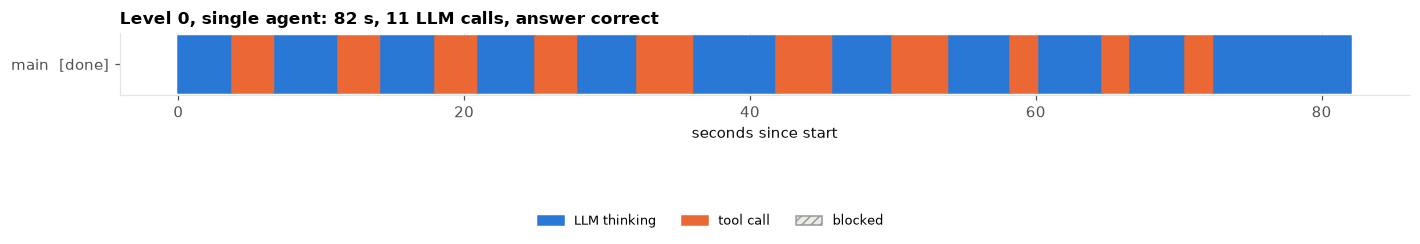

Trip plan (2 travellers, 2 nights per city)

FLIGHTS (cheapest per leg, price per person):
- Toronto -> Lisbon: TP 258, EUR 612 pp (EUR 1,224 for 2)
- Lisbon -> Rome: FR 2181, EUR 61 pp (EUR 122 for 2)
- Rome -> Prague: FR 3354, EUR 74 pp (EUR 148 for 2)
- Prague -> Toronto: LH 1397, EUR 580 pp (EUR 1,160 for 2)
Flights total: EUR 2,654

HOTELS (cheapest rated 4.0+, central preferred if at most EUR 10/night more; 2 nights, 1 shared room):
- Lisbon: Baixa Rooms, rating 4.1, central, EUR 96/night, EUR 192 total (cheapest 4.0+ hotel and already central)
- Rome: Termini Inn, rating 4.0, central, EUR 104/night, EUR 208 total (only EUR 6/night more than the cheapest 4.0+ option, Via Appia Lodge at EUR 98 in the outskirts, so the central one is chosen)
- Prague: Old Town Loft, rating 4.7, central, EUR 131/night, EUR 262 total (the only hotel rated 4.0+; Vltava Boat Hotel is 3.9 and Zizkov Hostel is 3.6)
Hotels total: EUR 662

MAY WEATHER:
- Lisbon: 22°C highs, about 6 rain days
- Rome: 24°C h

In [7]:
W_TOOLS = ["search_flights", "search_hotels", "get_weather"]
L0_ROLES = {"_main": "planner", "planner": {"model": MAIN_MODEL, "instructions": PLANNER, "actions": W_TOOLS + ["finish"]}}
rec0 = run_level("L0_single_agent", L0_ROLES, TRIP)
plot_timeline(rec0, "Level 0, single agent", FIG / "L0.png")
print(rec0["final"])

**What happened in this run.** Eleven LLM steps, strictly one after another: four flight searches, three hotel
searches, three weather calls, then the answer. Each step is a fresh `claude -p` process of about 4 seconds, so
LLM calls take about 52 of the 82 seconds and the simulated tools the other 30.

### Level 1: synchronous handoff
The main agent can `handoff` a city to a `city_researcher` subagent. `handoff` blocks until the subagent
returns, exactly like a function call. Contexts stay small (each subagent sees only its city), but nothing
runs in parallel: the grey hatched bars on the main row are time the planner spends doing nothing.

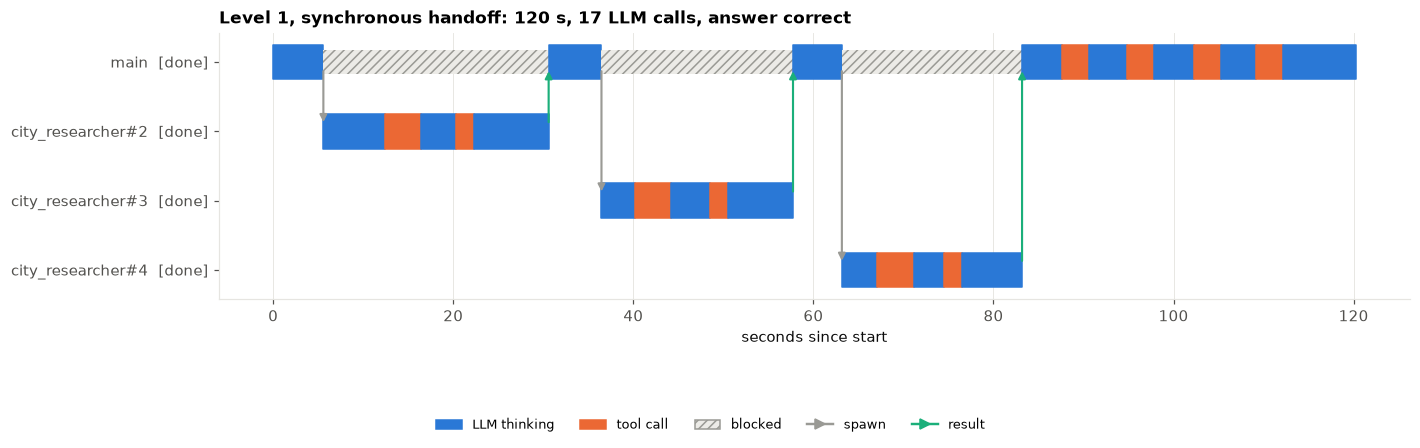

In [8]:
CITY = {"model": SUB_MODEL, "instructions": WORKER, "actions": ["search_hotels", "get_weather", "finish"]}
L1_ROLES = {"_main": "planner", "city_researcher": CITY,
            "planner": {"model": MAIN_MODEL, "instructions": PLANNER + " Hand each city's hotel and weather research "
                        "to a city_researcher with handoff; do the flights yourself.",
                        "actions": ["search_flights", "handoff", "finish"]}}
rec1 = run_level("L1_sync_handoff", L1_ROLES, TRIP)
plot_timeline(rec1, "Level 1, synchronous handoff", FIG / "L1.png")

**What happened in this run.** The planner handed off Lisbon, Rome and Prague one at a time and blocked on each
(the hatched bars: 66 s, 55% of the run), then searched the flights itself. Wall-clock rose from 82 s to 120 s:
the subagents add their own LLM steps and nothing runs in parallel. The Rome subagent returned both the cheapest
hotel and the central alternative, and the planner applied the €10 rule correctly.

### Level 2: asynchronous handoff, keep working, block only when needed
`spawn` returns a handle at once. The planner starts the three city researchers, does the flight searches
itself while they run, then calls `wait_all` (or `wait`) when it needs their answers. The subagents' results
arrive as messages; one that arrives while the planner is busy is held in its inbox and shown on its next step.

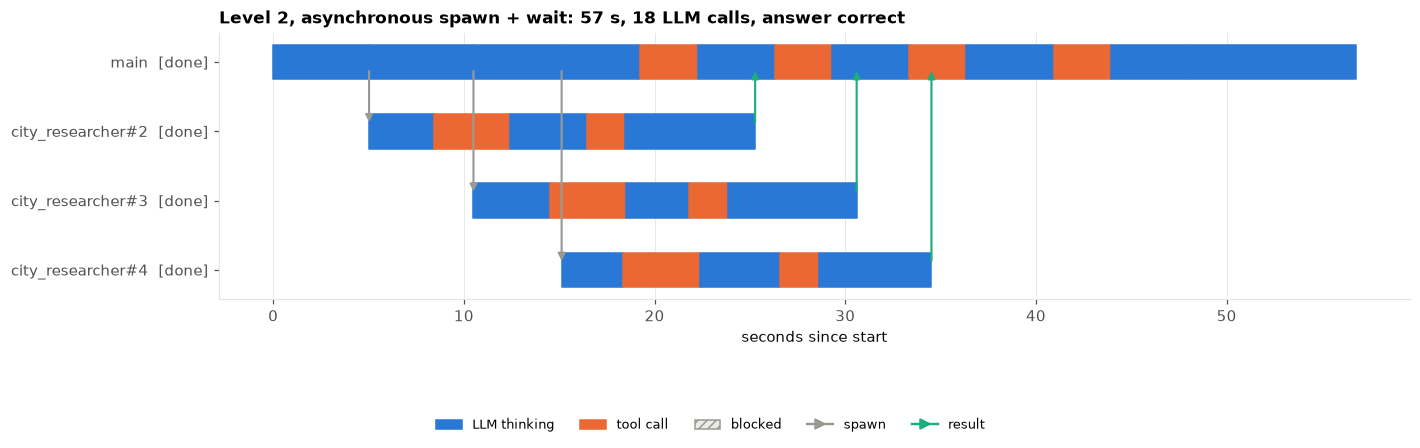

,t,kind,from,to,text
0,5.029,spawn,main,city_researcher#2,"City: Lisbon. May trip, 2 nights, 2 travellers..."
1,10.503,spawn,main,city_researcher#3,"City: Rome. May trip, 2 nights, 2 travellers s..."
2,15.126,spawn,main,city_researcher#4,"City: Prague. May trip, 2 nights, 2 travellers..."
3,25.274,result,city_researcher#2,main,"Cheapest hotel rated 4.0+: Baixa Rooms (4.1, c..."
4,30.598,result,city_researcher#3,main,"Rome, May, 2 nights, 1 room, 2 travellers (EUR..."
5,34.520,result,city_researcher#4,main,"Prague, May, 2 nights, 1 room shared by 2 trav..."


In [9]:
L2_ROLES = {"_main": "planner", "city_researcher": CITY,
            "planner": {"model": MAIN_MODEL, "max_depth": 1, "instructions": PLANNER + " Start one city_researcher "
                        "per city with spawn, search the flights yourself while they work, then collect their results.",
                        "actions": ["search_flights", "spawn", "wait", "wait_all", "finish"]}}
rec2 = run_level("L2_async_spawn", L2_ROLES, TRIP)
plot_timeline(rec2, "Level 2, asynchronous spawn + wait", FIG / "L2.png")
messages_table(rec2, ("spawn", "result"))

**What happened in this run.** The planner spawned the three researchers in its first three steps and went
straight to the flights. Lisbon's result arrived during the second flight search, Rome's and Prague's during the
third. When the planner called `wait_all`, all three results were already in its inbox, so it never blocked.
57 s against 82 s for the single agent, for 18 LLM calls instead of 11.

## 7. Levels 3-4: messages in both directions
### Level 3: progress reports up, instructions down
Now subagents `report` progress to the planner without stopping, and the planner can `send` instructions to a
running subagent. To make the channel matter, the hotel search for **Prague fails** on its first call (HTTP
503). The Prague researcher is told to report a failure and `wait_for_message`; the planner, which keeps
working on flights, decides what to do (for example: use `search_hotels_backup`). The failure report is sent
with `urgent: true`, so it wakes the planner even if the planner is already blocked in `wait_all`.

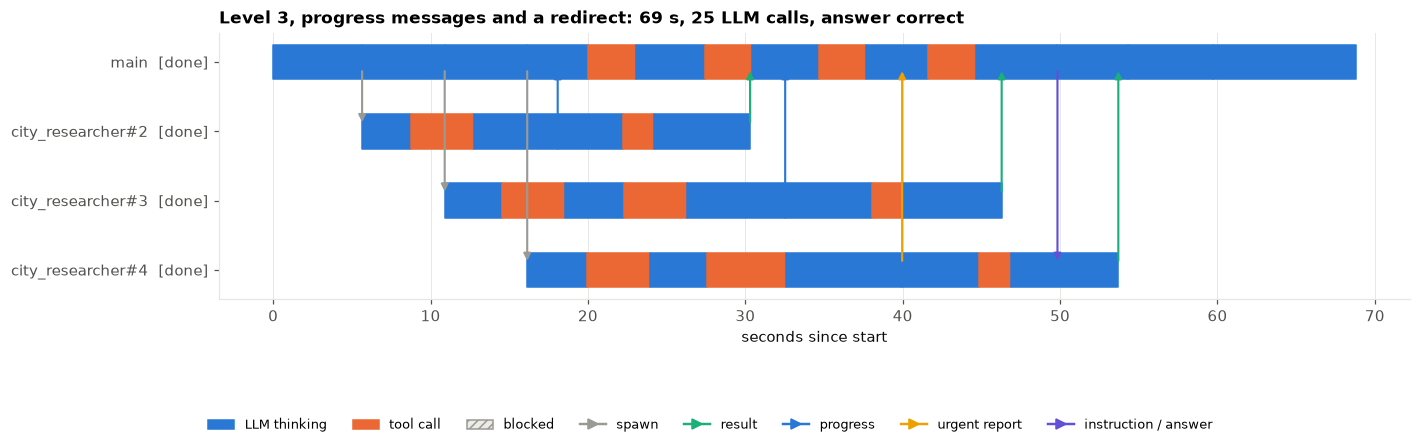

,t,kind,from,to,text
0,18.077,progress,city_researcher#2,main,Lisbon search_hotels returned 3 hotels. Cheape...
1,32.532,progress,city_researcher#3,main,Hotel search done. Cheapest 4.0+: Via Appia Lo...
2,49.833,instruction,main,city_researcher#4,"Proceed with the backup data, no need to retry..."


In [10]:
CITY3 = {"model": SUB_MODEL, "instructions": WORKER + " After each search, report a one-line progress update to "
         "your parent. If a tool fails, report the error with urgent=true and wait_for_message for "
         "instructions; do not guess.",
         "actions": ["search_hotels", "search_hotels_backup", "get_weather", "report", "wait_for_message", "finish"]}
L3_ROLES = {"_main": "planner", "city_researcher": CITY3,
            "planner": {"model": MAIN_MODEL, "max_depth": 1, "instructions": PLANNER + " Start one city_researcher per "
                        "city with spawn, search flights yourself, and read their progress messages. If a subagent "
                        "reports a problem, send it instructions (a backup hotel search exists: search_hotels_backup).",
                        "actions": ["search_flights", "spawn", "send", "wait", "wait_all", "finish"]}}
rec3 = run_level("L3_progress_and_redirect", L3_ROLES, TRIP, world={"hotel_search_fails": {"Prague"}})
plot_timeline(rec3, "Level 3, progress messages and a redirect", FIG / "L3.png")
messages_table(rec3, ("progress", "instruction"))

**What happened in this run.** The Prague researcher's first hotel search failed with HTTP 503. Instead of
stopping as instructed, it switched to `search_hotels_backup` on its own, sent an urgent report at 40 s saying
so, and carried on with the weather search. The planner read the report on its next step and at 50 s told it to
go ahead with the backup data, but the researcher was already writing its final answer and never read that
message (its last step shows no new messages). The channel worked; the cheap subagent did not follow the "wait
for instructions" rule, and the harness gave the planner no sign that its message arrived too late.
The Lisbon and Rome researchers sent ordinary progress reports. 69 s, 25 LLM calls.

### Level 4: a subagent asks, and blocks until the planner answers
This time the planner is told **not** to pass on the user's location preference. A city researcher that finds
two acceptable hotels within €10 of each other has to `ask_parent`, which blocks the researcher until the
planner replies with `send`. The planner is not blocked: it sees the question on its next step, in between its
own flight searches.

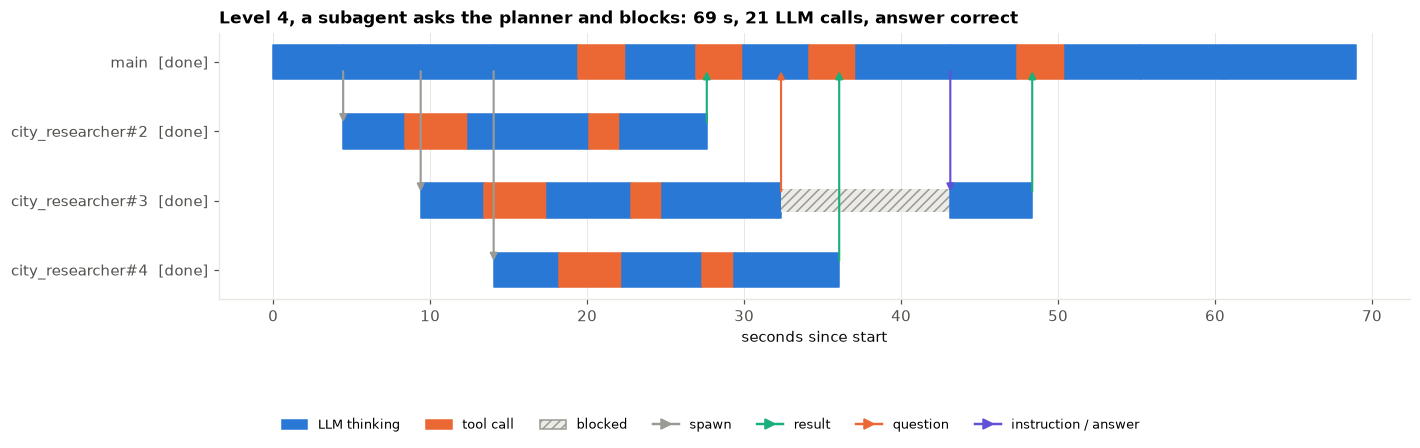

,t,kind,from,to,text
0,32.351,question,city_researcher#3,main,Rome: two hotels rated 4.0+ are within EUR 10 ...
1,43.135,instruction,main,city_researcher#3,"Report Termini Inn (central, EUR 104/night) as..."


In [11]:
TRIP4 = TRIP + (" When you delegate, give subagents only the city and the rating rule; they must ask you if a "
                 "choice depends on the travellers' preferences.")
CITY4 = {"model": SUB_MODEL, "instructions": WORKER + " Pick the cheapest hotel rated 4.0 or higher. If two "
         "acceptable hotels are within EUR 10 per night of each other, ask your parent which to choose before finishing.",
         "actions": ["search_hotels", "get_weather", "ask_parent", "finish"]}
L4_ROLES = {"_main": "planner", "city_researcher": CITY4,
            "planner": {"model": MAIN_MODEL, "max_depth": 1, "instructions": PLANNER + " Start one city_researcher per "
                        "city with spawn and search flights yourself. Subagents may ask you questions; answer them "
                        "with send. Answering promptly unblocks them.",
                        "actions": ["search_flights", "spawn", "send", "wait", "wait_all", "finish"]}}
rec4 = run_level("L4_child_asks_parent", L4_ROLES, TRIP4)
plot_timeline(rec4, "Level 4, a subagent asks the planner and blocks", FIG / "L4.png")
messages_table(rec4, ("question", "instruction"))

**What happened in this run.** Lisbon and Prague had no close call and finished on their own. The Rome
researcher found Via Appia Lodge (€98, outskirts) and Termini Inn (€104, central) within €10 of each other and
asked at 32 s. The planner was between flight searches; it saw the question on its next step and answered at
43 s. The Rome researcher was blocked for those 11 s (hatched bar); the planner never stopped working.

## 8. Levels 5-6: racing and nested delegation
### Level 5: hedging with `wait_any` and `cancel`
Three `flight_scout` subagents search the same four legs through providers of very different speed (2 s, 6 s
and 14 s per call). The planner takes the first complete answer with `wait_any` and cancels the others. This is
the pattern for flaky or slow back ends. The task here is flights only.

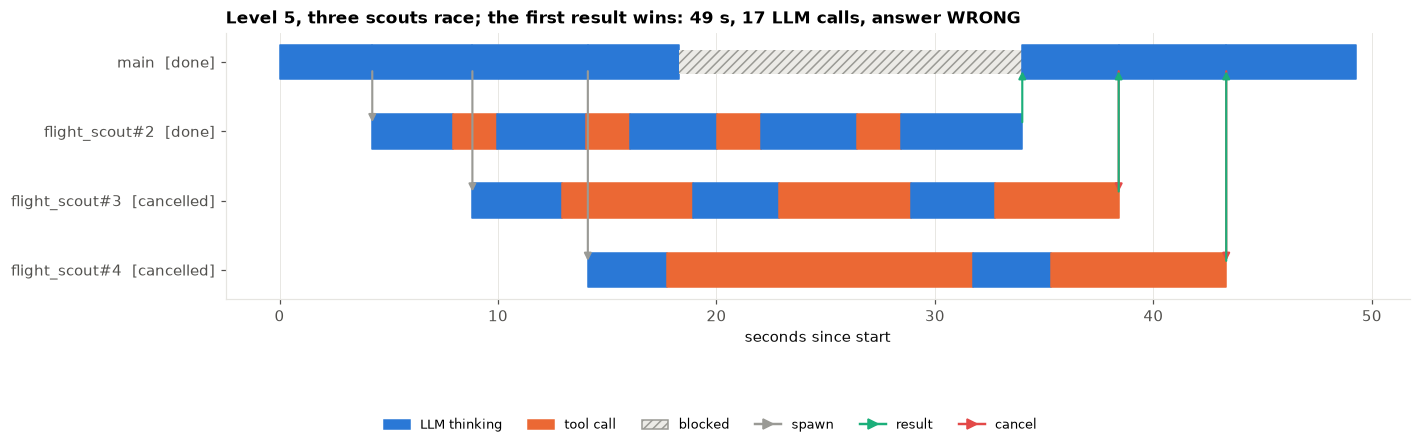

Expected flight total: €2,654. Planner answer: Cheapest flight per leg (per person, EUR), from skyscan: Toronto->Lisbon TP 258 at 612; Lisbon->Rome FR 2181 at 61; Rome->Prague FR 3354 at 74; Prague->Toronto LH 1397 at 580. Per-person total: 1327 EUR. Total for 2 travellers: 2654 EUR. Only skyscan's results were used. It answered first, so the farefinder and airdeal scouts were cancelled and their prices were not compared.


In [12]:
FLIGHTS_ONLY = ("Find the cheapest flight for each leg of Toronto -> Lisbon -> Rome -> Prague -> Toronto and the "
                "total flight cost for 2 travellers in EUR. Start three flight_scout subagents, one per provider "
                "(skyscan, farefinder, airdeal; put the provider name in the task), use whichever answers first and "
                "cancel the others.")
SCOUT = {"model": SUB_MODEL, "instructions": WORKER, "actions": ["search_flights_provider", "finish"]}
L5_ROLES = {"_main": "planner", "flight_scout": SCOUT,
            "planner": {"model": MAIN_MODEL, "max_depth": 1, "instructions": PLANNER,
                        "actions": ["spawn", "wait_any", "cancel", "finish"]}}

rec5 = run_level("L5_race_and_cancel", L5_ROLES, FLIGHTS_ONLY)
plot_timeline(rec5, "Level 5, three scouts race; the first result wins", FIG / "L5.png")
flights_total = sum(min(p for _, p in o) for o in FLIGHTS.values()) * 2
print(f"Expected flight total: €{flights_total:,}. Planner answer: {rec5['final']}")

**What happened in this run.** skyscan (2 s per search) finished first. The planner, blocked in `wait_any` for
16 s, took its answer and cancelled the farefinder and airdeal scouts in the middle of their searches; both
stopped at their next cancellation check. 49 s for the correct flight total. With only the slowest provider,
the four searches alone would take 56 s.

### Level 6: nested delegation
The planner spawns one `city_planner` per city, and each city planner spawns its own `hotel_scout` and
`weather_scout`. Results travel two hops: scout → city planner → planner. Depth is capped (`max_depth`), which
is the simplest guard against runaway recursion.

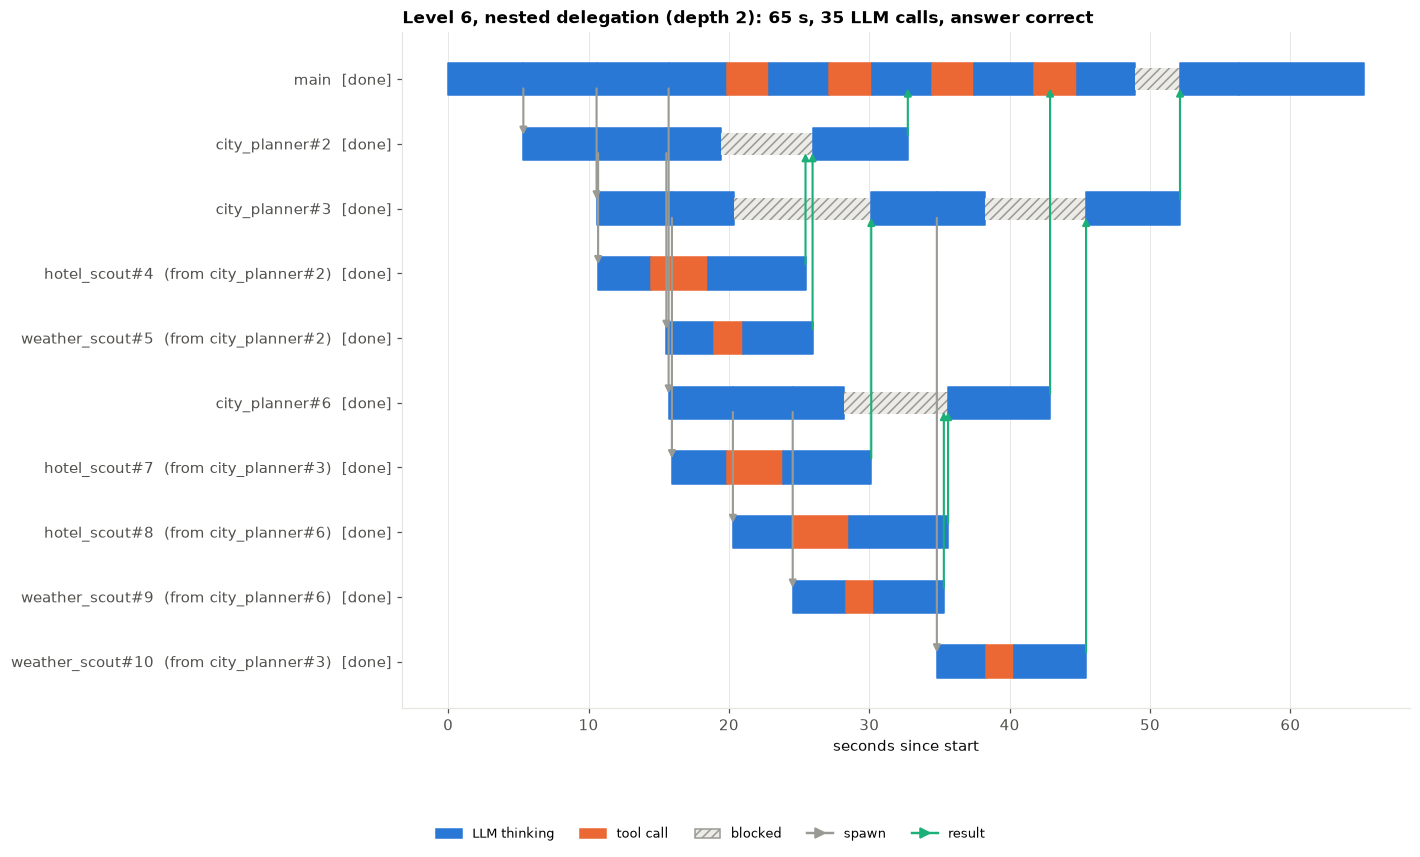

In [13]:
L6_ROLES = {
    "_main": "planner",
    "planner": {"model": MAIN_MODEL, "max_depth": 1, "instructions": PLANNER + " Start one city_planner per city with "
                "spawn (include the hotel rule and the central-location preference in its task), do the flights "
                "yourself, then collect their results.", "actions": ["search_flights", "spawn", "wait", "wait_all", "finish"]},
    "city_planner": {"model": SUB_MODEL, "max_depth": 2, "instructions": "You manage one city. Spawn a hotel_scout and a "
                     "weather_scout, wait for both, choose the hotel by the rule in your task, then finish.",
                     "actions": ["spawn", "wait", "wait_all", "finish"]},
    "hotel_scout": {"model": SUB_MODEL, "instructions": WORKER, "actions": ["search_hotels", "finish"]},
    "weather_scout": {"model": SUB_MODEL, "instructions": WORKER, "actions": ["get_weather", "finish"]},
}
rec6 = run_level("L6_nested", L6_ROLES, TRIP)
plot_timeline(rec6, "Level 6, nested delegation (depth 2)", FIG / "L6.png")

**What happened in this run.** Ten agents and 35 LLM calls. The city planners spent most of their time blocked
on their scouts, and each scout made a single tool call. The answer was correct after 65 s: faster than one agent,
slower than level 2, because every hop adds an LLM step at both ends. The final answer also lists low
temperatures and rainfall totals that no tool returned (the answer labels them as general climate norms). Each
extra layer is one more place where content that no tool produced can enter.

## 9. Comparison across levels
For each run: wall-clock time, LLM calls, tool calls, the share of the main agent's time spent blocked, and
whether the final answer has the right total and hotels. Level 5 solves a smaller task (flights only), so its
row is not comparable on time.

In [14]:
RECS = {"0 single agent": rec0, "1 sync handoff": rec1, "2 async spawn": rec2, "3 progress + redirect": rec3,
        "4 child asks parent": rec4, "5 race + cancel": rec5, "6 nested": rec6}


def metrics(rec):
    main_spans = [s for s in rec["spans"] if s["agent"] == "main"]
    blocked = sum(s["end"] - s["start"] for s in main_spans if s["kind"] == "blocked")
    llm_s = sum(s["end"] - s["start"] for s in rec["spans"] if s["kind"] == "llm")
    tool_s = sum(s["end"] - s["start"] for s in rec["spans"] if s["kind"] == "tool")
    msgs = [e for e in rec["events"] if e["kind"] in ("progress", "question", "instruction", "result")]
    is_flights = rec["level"].startswith("L5")
    correct = (str(flights_total) in (rec["final"] or "").replace(",", "")) if is_flights else check(rec)["correct"]
    return {"wall s": rec["wall_s"], "agents": len(rec["agents"]), "LLM calls": rec["calls"]["llm"],
            "tool calls": rec["calls"]["tool"], "LLM s (summed)": llm_s, "tool s (summed)": tool_s,
            "main blocked s": blocked, "main blocked %": blocked / rec["wall_s"] if rec["wall_s"] else 0,
            "messages": len(msgs), "correct": correct}


cmp = pd.DataFrame({k: metrics(r) for k, r in RECS.items()}).T
cmp.to_csv(DATA / "comparison.csv")
cmp.style.format({"wall s": "{:.0f}", "LLM s (summed)": "{:.0f}", "tool s (summed)": "{:.0f}", "main blocked s": "{:.0f}",
                  "main blocked %": "{:.0%}"})

,wall s,agents,LLM calls,tool calls,LLM s (summed),tool s (summed),main blocked s,main blocked %,messages,correct
0 single agent,82,1,11,10,52,30,0,0%,0,True
1 sync handoff,120,4,17,10,90,30,66,55%,3,True
2 async spawn,57,4,18,10,86,30,0,0%,3,True
3 progress + redirect,69,4,25,12,127,39,0,0%,6,True
4 child asks parent,69,4,21,10,112,30,0,0%,5,True
5 race + cancel,49,4,17,9,74,48,16,32%,3,True
6 nested,65,10,35,10,173,30,3,5%,9,True


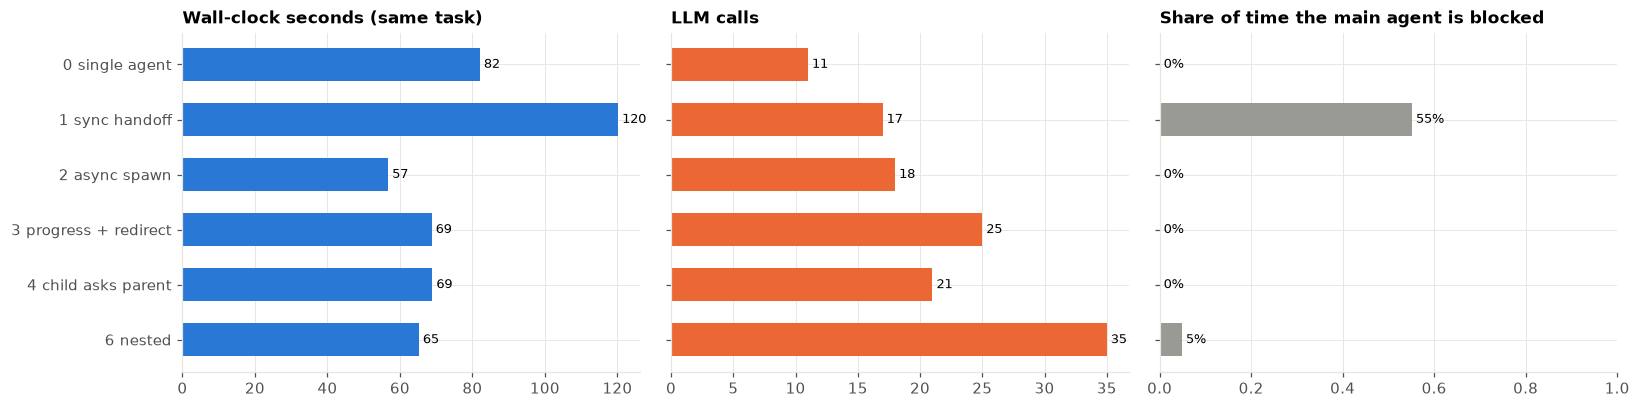

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
c = cmp.drop(index=[i for i in cmp.index if i.startswith("5")])
labels = list(c.index)
axes[0].barh(labels, c["wall s"].astype(float), color=PALETTE[0], height=0.6); axes[0].invert_yaxis()
axes[0].set_title("Wall-clock seconds (same task)")
axes[1].barh(labels, c["LLM calls"].astype(float), color=PALETTE[1], height=0.6); axes[1].invert_yaxis()
axes[1].set_title("LLM calls"); axes[1].set_yticklabels([])
axes[2].barh(labels, c["main blocked %"].astype(float), color="#9a9a95", height=0.6); axes[2].invert_yaxis()
axes[2].set_xlim(0, 1); axes[2].set_title("Share of time the main agent is blocked"); axes[2].set_yticklabels([])
for ax, col, fmt in [(axes[0], "wall s", "{:.0f}"), (axes[1], "LLM calls", "{:.0f}"), (axes[2], "main blocked %", "{:.0%}")]:
    for i, v in enumerate(c[col].astype(float)):
        ax.text(v, i, " " + fmt.format(v), va="center", fontsize=8.5)
plt.tight_layout(); fig.savefig(FIG / "comparison.png"); plt.show()

### 9.1 Where the time goes
Summed over all agents: LLM thinking versus tool time versus time blocked. Parallel levels spend more
agent-seconds in total but less wall-clock time; the blocked share is the price of coordination.

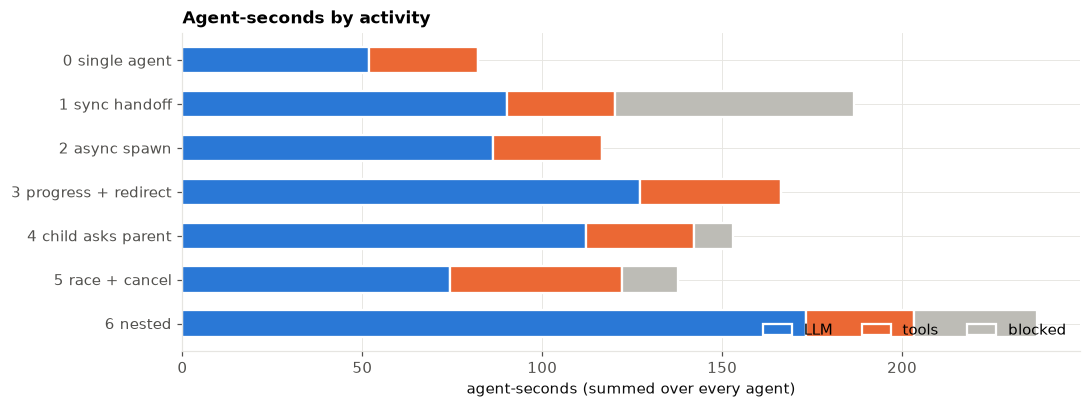

In [16]:
tot = pd.DataFrame({k: {"LLM": sum(s["end"] - s["start"] for s in r["spans"] if s["kind"] == "llm"),
                        "tools": sum(s["end"] - s["start"] for s in r["spans"] if s["kind"] == "tool"),
                        "blocked": sum(s["end"] - s["start"] for s in r["spans"] if s["kind"] == "blocked")}
                    for k, r in RECS.items()}).T
fig, ax = plt.subplots(figsize=(10, 3.8))
left = np.zeros(len(tot))
for col, color in zip(["LLM", "tools", "blocked"], [PALETTE[0], PALETTE[1], "#bdbcb6"]):
    ax.barh(tot.index, tot[col], left=left, color=color, height=0.6, label=col, edgecolor="white", linewidth=1.5)
    left += tot[col].values
ax.invert_yaxis(); ax.set_xlabel("agent-seconds (summed over every agent)"); ax.legend(ncol=3, loc="lower right")
ax.set_title("Agent-seconds by activity")
plt.tight_layout(); plt.show()

### 9.2 What the agents actually said
The main agent's decisions in Level 4, step by step: each action, and the messages it saw at that step.

In [17]:
pd.DataFrame([{"step": h["step"], "action": h["action"].get("action"), "args": json.dumps(h["action"].get("args"))[:110],
               "messages seen": "; ".join(f"{m['from']}:{m['type']}" for m in h["seen"]), "result": str(h["result"])[:90]}
              for h in rec4["agents"]["main"]["history"]])

,step,action,args,messages seen,result
0,1,spawn,"{""role"": ""city_researcher"", ""task"": ""City: Lis...",,started city_researcher#2
1,2,spawn,"{""role"": ""city_researcher"", ""task"": ""City: Rom...",,started city_researcher#3
2,3,spawn,"{""role"": ""city_researcher"", ""task"": ""City: Pra...",,started city_researcher#4
3,4,search_flights,"{""origin"": ""Toronto"", ""destination"": ""Lisbon""}",,"[{""flight"": ""TP 258"", ""price_eur_per_person"": ..."
4,5,search_flights,"{""origin"": ""Lisbon"", ""destination"": ""Rome""}",,"[{""flight"": ""TP 838"", ""price_eur_per_person"": ..."
5,6,search_flights,"{""origin"": ""Rome"", ""destination"": ""Prague""}",city_researcher#2:result,"[{""flight"": ""OK 5813"", ""price_eur_per_person"":..."
6,7,send,"{""handle"": ""city_researcher#3"", ""text"": ""Repor...",city_researcher#3:question; city_researcher#4:...,sent to city_researcher#3
7,8,search_flights,"{""origin"": ""Prague"", ""destination"": ""Toronto""}",,"[{""flight"": ""LH 1397"", ""price_eur_per_person"":..."
8,9,wait_all,"{""handles"": [""city_researcher#2"", ""city_resear...",city_researcher#3:result,city_researcher#2: Lisbon. Cheapest hotel rate...
9,10,wait,"{""handle"": ""city_researcher#3"", ""timeout_s"": 60}",,city_researcher#3 returned: Rome: Pick Termini...


## 10. Design notes, limitations, reproduction
**What the levels show**
* Every agent step here is a separate `claude -p` process of about 4 seconds, which is why LLM time (blue)
  dominates the timelines. A harness that keeps one API connection per agent would be faster; the coordination
  patterns would not change.
* A synchronous handoff (level 1) is a function call: it shrinks each agent's context but does not save time.
* The gain comes from not blocking (level 2): the planner works while subagents run, and blocks only at the point
  where it needs their results.
* A message sent to an agent that has already finished is lost without notice here (level 3). A production
  harness should return a delivery status, or route late messages back to the sender.
* Two-way messages (levels 3-4) let a subagent stop and ask instead of guessing. The cost is that a blocked
  subagent depends on the planner checking its inbox; a planner that is itself blocked in a long `wait` cannot
  answer, so `wait` should have a timeout and the planner should prefer short waits while questions may come.
* Racing (level 5) trades extra calls for latency, and only works if cancellation actually stops the losers.
* Nesting (level 6) adds a hop per level to every result; with a cheap model in the middle layer, each hop is
  also a place where instructions can get lost.

**Limitations**
* One recorded run per level. LLM agents are not deterministic; a re-run can take a different path, more steps,
  or a wrong turn. The timings are illustrative, not benchmarks.
* Tools are simulated with fixed delays. Real APIs have variable latency and partial failures.
* The harness is a teaching implementation: threads instead of async I/O, no persistence of agent state across
  process restarts, and no resource limits beyond `MAX_STEPS`, `max_depth` and timeouts.

**Reproduce.** Run all cells to replay the recorded runs from `data/runs/`. Set `NB_LIVE=1` in the environment
(or `LIVE = True`) to run the agents again through the `claude` CLI (or set `BACKEND` to `codex` or `muse`).